# 🔍 K-Nearest Neighbours (KNN) from Scratch

**Goal:** Classify a new point by looking at the $k$ closest training examples and taking a majority vote.

---

## 1. Algorithm Intuition

KNN is a **lazy learner** — it stores all training examples and defers computation to prediction time. There is no explicit training phase.

**Prediction for a query point $\mathbf{x}^*$:**
1. Compute the distance from $\mathbf{x}^*$ to every training point.
2. Select the $k$ training points with the smallest distances.
3. Return the most frequent class among those $k$ neighbours.

**Euclidean Distance:**
$$d(\mathbf{x}^{(i)}, \mathbf{x}^*) = \sqrt{\sum_{j=1}^{n} (x_j^{(i)} - x_j^*)^2}$$

**Variable glossary:**
| Symbol | Meaning |
|--------|---------|
| $k$ | number of neighbours to consider |
| $m$ | number of training examples |
| $n$ | number of features |
| $d(\cdot, \cdot)$ | distance metric (Euclidean here) |

**Key insight on $k$:**
- **Small $k$** → complex boundary → high variance (overfitting).
- **Large $k$** → smooth boundary → high bias (underfitting).

---

## 2. Normalisation is Critical

KNN relies entirely on distances. If one feature ranges over [0, 1000] and another over [0, 1], the large-scale feature will dominate the distance. **Always normalise before using KNN.**


## 3. Imports

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(21)
plt.style.use('seaborn-v0_8-whitegrid')

## 4. Synthetic Multi-Class Data

In [2]:
# Three-class blob dataset: 2 features so we can visualise
def make_blobs(n_per_class, centers, std=0.8, seed=21):
    """
    Generate multi-class blob data.

    Parameters
    ----------
    n_per_class : int
    centers     : list of (cx, cy) tuples, one per class
    std         : float — spread of each blob

    Returns
    -------
    X : ndarray (m, 2)
    y : ndarray (m,) — integer class labels 0, 1, 2, ...
    """
    rng = np.random.default_rng(seed)
    X_list, y_list = [], []
    for label, (cx, cy) in enumerate(centers):
        pts = rng.normal(loc=[cx, cy], scale=std, size=(n_per_class, 2))
        X_list.append(pts)
        y_list.append(np.full(n_per_class, label))
    X = np.vstack(X_list)
    y = np.hstack(y_list)
    perm = rng.permutation(len(y))
    return X[perm], y[perm]

centers = [(-3, 0), (0, 3), (3, 0)]
X_all, y_all = make_blobs(n_per_class=100, centers=centers)

print(f"X shape: {X_all.shape}, y shape: {y_all.shape}")
print(f"Classes: {np.unique(y_all)}")

X shape: (300, 2), y shape: (300,)
Classes: [0 1 2]


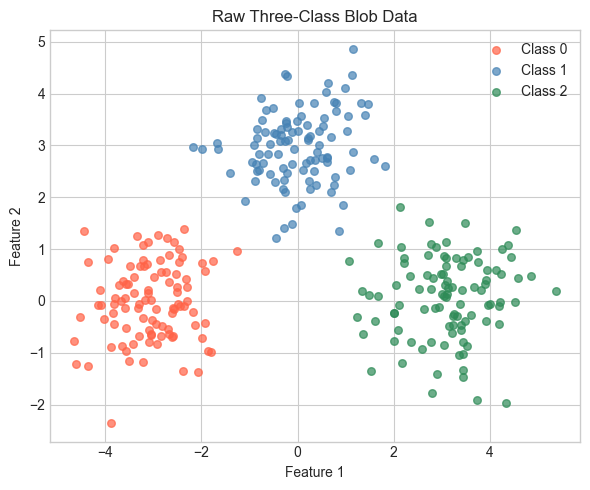

In [3]:
# Plot raw data
colors = ['tomato', 'steelblue', 'seagreen']
fig, ax = plt.subplots(figsize=(6, 5))
for cls in range(3):
    mask = y_all == cls
    ax.scatter(X_all[mask, 0], X_all[mask, 1],
               color=colors[cls], label=f'Class {cls}', alpha=0.7, s=30)
ax.set_title('Raw Three-Class Blob Data')
ax.set_xlabel('Feature 1')
ax.set_ylabel('Feature 2')
ax.legend()
plt.tight_layout()
plt.show()

## 5. Train / Test Split and Normalisation

In [4]:
def train_test_split(X, y, test_ratio=0.2, seed=7):
    rng = np.random.default_rng(seed)
    idx = rng.permutation(len(y))
    s = int(len(y) * (1 - test_ratio))
    return X[idx[:s]], X[idx[s:]], y[idx[:s]], y[idx[s:]]

def normalize(X_train, X_test):
    mu    = X_train.mean(axis=0)
    sigma = X_train.std(axis=0)
    sigma[sigma == 0] = 1
    return (X_train - mu) / sigma, (X_test - mu) / sigma, mu, sigma

X_train, X_test, y_train, y_test = train_test_split(X_all, y_all)
X_train_n, X_test_n, mu, sigma   = normalize(X_train, X_test)
print(f"Train: {X_train_n.shape}, Test: {X_test_n.shape}")

Train: (240, 2), Test: (60, 2)


## 6. KNN Distance and Prediction

In [5]:
def euclidean_distance(a, b):
    """
    Euclidean distance between two 1-D vectors a and b.
    d = sqrt( sum( (a_j - b_j)^2 ) )
    """
    return np.sqrt(np.sum((a - b) ** 2))

In [6]:
def knn_predict_one(x_query, X_train, y_train, k):
    """
    Predict the class for a single query point x_query.

    Steps:
      1. Compute distance from x_query to every training point.
      2. Find the k closest training points.
      3. Return the majority class among those k neighbours.

    Parameters
    ----------
    x_query : ndarray (n,)
    X_train : ndarray (m, n)
    y_train : ndarray (m,)  — integer labels
    k       : int

    Returns
    -------
    predicted_class : int
    """
    # Step 1: distances to all training points
    distances = np.array([euclidean_distance(x_query, x_tr) for x_tr in X_train])

    # Step 2: indices of k smallest distances
    k_nearest_idx = np.argsort(distances)[:k]

    # Step 3: majority vote
    k_nearest_labels = y_train[k_nearest_idx]
    classes, counts  = np.unique(k_nearest_labels, return_counts=True)
    return int(classes[np.argmax(counts)])

In [7]:
def knn_predict(X_query, X_train, y_train, k):
    """
    Predict classes for multiple query points.

    Returns
    -------
    predictions : ndarray (q,)
    """
    return np.array([knn_predict_one(xq, X_train, y_train, k)
                     for xq in X_query])

## 7. Predict on Test Set (k=5)

In [8]:
k = 5
y_pred_test = knn_predict(X_test_n, X_train_n, y_train.astype(int), k)
print(f"Predictions (first 20): {y_pred_test[:20]}")
print(f"Ground truth (first 20): {y_test[:20].astype(int)}")

Predictions (first 20): [2 1 0 0 0 0 0 1 0 0 2 1 0 0 2 1 2 1 0 0]
Ground truth (first 20): [2 1 0 0 0 0 0 1 0 0 2 1 0 0 2 1 2 1 0 0]


## 8. Decision Boundary Visualisation

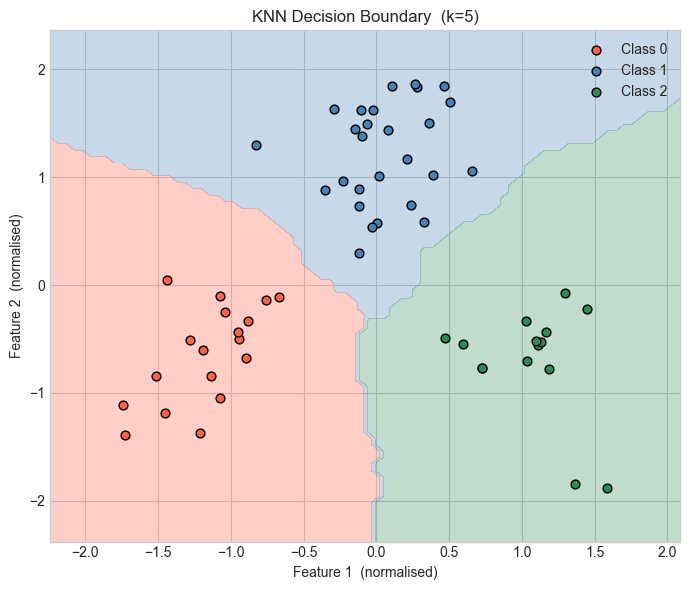

In [9]:
# Build a coarse grid for visualisation (fine grid would be very slow for pure-Python KNN)
resolution = 80
x1_min, x1_max = X_test_n[:, 0].min() - 0.5, X_test_n[:, 0].max() + 0.5
x2_min, x2_max = X_test_n[:, 1].min() - 0.5, X_test_n[:, 1].max() + 0.5
xx, yy = np.meshgrid(np.linspace(x1_min, x1_max, resolution),
                     np.linspace(x2_min, x2_max, resolution))
grid_pts   = np.c_[xx.ravel(), yy.ravel()]
grid_preds = knn_predict(grid_pts, X_train_n, y_train.astype(int), k)
grid_preds = grid_preds.reshape(xx.shape)

fig, ax = plt.subplots(figsize=(7, 6))
ax.contourf(xx, yy, grid_preds, alpha=0.3,
            levels=[-0.5, 0.5, 1.5, 2.5],
            colors=['tomato', 'steelblue', 'seagreen'])
for cls in range(3):
    mask = y_test.astype(int) == cls
    ax.scatter(X_test_n[mask, 0], X_test_n[mask, 1],
               color=colors[cls], edgecolors='k', s=40, label=f'Class {cls}')
ax.set_xlabel('Feature 1  (normalised)')
ax.set_ylabel('Feature 2  (normalised)')
ax.set_title(f'KNN Decision Boundary  (k={k})')
ax.legend()
plt.tight_layout()
plt.show()

## 9. Evaluation Metrics

In [10]:
def accuracy(y_true, y_pred):
    return np.mean(y_true.astype(int) == y_pred.astype(int))

def multiclass_confusion_matrix(y_true, y_pred, n_classes):
    cm = np.zeros((n_classes, n_classes), dtype=int)
    for true_label, pred_label in zip(y_true.astype(int), y_pred.astype(int)):
        cm[true_label][pred_label] += 1
    return cm

acc = accuracy(y_test, y_pred_test)
cm  = multiclass_confusion_matrix(y_test, y_pred_test, n_classes=3)

print(f"Test Accuracy (k={k}): {acc:.4f}")
print("\nConfusion Matrix (rows=actual, cols=predicted):")
header = '        ' + '  '.join([f'Pred {c}' for c in range(3)])
print(header)
for i, row in enumerate(cm):
    print(f"Actual {i}  " + '  '.join([f'{v:6d}' for v in row]))

Test Accuracy (k=5): 1.0000

Confusion Matrix (rows=actual, cols=predicted):
        Pred 0  Pred 1  Pred 2
Actual 0      18       0       0
Actual 1       0      27       0
Actual 2       0       0      15


## 10. Effect of k on Accuracy

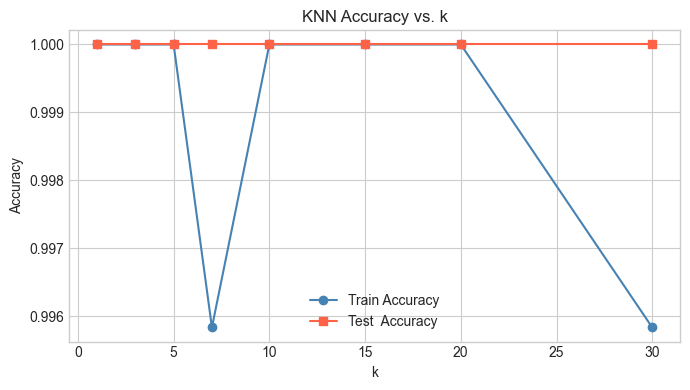

Best k=1  →  Test Accuracy=1.0000


In [11]:
k_values    = [1, 3, 5, 7, 10, 15, 20, 30]
train_accs  = []
test_accs   = []

for kv in k_values:
    y_pred_tr = knn_predict(X_train_n, X_train_n, y_train.astype(int), kv)
    y_pred_te = knn_predict(X_test_n,  X_train_n, y_train.astype(int), kv)
    train_accs.append(accuracy(y_train, y_pred_tr))
    test_accs.append(accuracy(y_test,  y_pred_te))

plt.figure(figsize=(7, 4))
plt.plot(k_values, train_accs, marker='o', label='Train Accuracy', color='steelblue')
plt.plot(k_values, test_accs,  marker='s', label='Test  Accuracy', color='tomato')
plt.xlabel('k')
plt.ylabel('Accuracy')
plt.title('KNN Accuracy vs. k')
plt.legend()
plt.tight_layout()
plt.show()

best_k   = k_values[int(np.argmax(test_accs))]
best_acc = max(test_accs)
print(f"Best k={best_k}  →  Test Accuracy={best_acc:.4f}")

## 11. Observations and Limitations

### What we observed
- KNN with $k=1$ achieves 100% training accuracy (memorises every point) but generalises worse.
- As $k$ grows, the boundary smooths out, trading variance for bias.
- The optimal $k$ achieves the best balance on the test set.

### Limitations
| Limitation | Description |
|------------|-------------|
| **Slow prediction** | Must compute distances to every training point for each query. |
| **High memory** | Stores all training data at inference time. |
| **Curse of dimensionality** | Distances become meaningless in high-dimensional spaces. |
| **Scale sensitivity** | Requires normalisation; large-scale features dominate distance. |
| **Choosing k** | Requires cross-validation; no closed-form optimal $k$. |
